# Can internal knobs beat temperature for novel code? — demo notebook

**Question.** Is temperature really the "creativity knob" of an LLM? Can steering the model's *internal*
activations make it write more diverse, novel algorithms that still work?

**Set-up of the original experiment (`method.py`, INFLUENCE ARM).** Qwen2.5-3B-Instruct writes Python code for two tasks:

* **T1** – *"Implement a path search algorithm"* (`find_path(graph, start, goal)`)
* **T3** – *"Implement a function that finds a shortest path in a weighted graph"* (`shortest_path(graph, source, target)`)

Every program is

1. labelled with an **idea** (BFS, DFS, Dijkstra, A*, SPFA, …) by a deterministic AST classifier (`protocol/classifier.py`), and
2. checked by a sandboxed **execution oracle** on 50 fixed random graphs; *pass* = all 50 correct (`protocol/oracle.py`).

The full pipeline compares practitioner knobs with internal knobs. All conditions use the same seeded sampler, so they share common random numbers.

* Practitioner knobs: temperature, top-k, "make a new algorithm" prompts, a ban on the top-3 ideas, generate-then-select.
* Internal knobs: H-flatten steering directions, A3 rank-1 projection and LEACE erasure of the "idea" subspace, an A4 "unusualness" dial.
* Controls: matched-norm random directions.

**Headline of the full run.** No internal knob survives the pre-registered rules, so the result is a "prompting ceiling".
The H directions *select* a known idea rather than flatten the choice. For example, H-dim α=0.224 turns T1 into DFS 145/150.
Judge-confirmed novel-and-correct programs: **0 in every condition**.

**What this notebook runs.** The GPU stages need hours on an H100 and are not run here: 300 baselines per task,
activation caching, probes, vector building and a sweep of more than 70 settings. The notebook runs the parts that work on a CPU:

1. the **original scorer** (classifier + oracle) re-scoring stored generations from the run;
2. the original **`stage_baseline`** aggregation (idea menus, ban-top-3 prompt) on the re-scored records;
3. the original **setting registry** and the **metric/eligibility/selection** logic over the stored per-setting labels
   of every sweep condition (seeds 0..49 of each task);
4. *(optional)* the original **generation engine** (seeded inverse-CDF sampler, code-stop, steering hook) and `Runner`,
   live on a small model. It compares plain T=0.7, T=1.6/top-k=10 and a matched-norm random steering direction under the *same seed*.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install
_pip('loguru==0.7.3')

# numpy, matplotlib, torch, transformers — pre-installed on Colab, install locally only (Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0', 'transformers==5.0.0', 'huggingface_hub==1.4.0', 'tokenizers==0.22.2')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')

## Imports
The original `method.py` import block, plus the imports of the helper modules that are inlined below
(`protocol/oracle.py`, `protocol/classifier.py`, `src/common.py`, `src/engine.py`) and matplotlib for the plots.

In [2]:
# ---- original method.py imports ----
import argparse
import gc
import json
import math
import random
import re
import sys
import time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np

from loguru import logger

# ---- imports used by the inlined helper modules ----
import ast
import hashlib
import heapq
import os
import resource
import shutil
import subprocess
import tempfile
from collections import deque
from dataclasses import asdict, dataclass, field

# ---- notebook additions ----
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-8d19e3-temperature-flattens-ideas-context/main/round-1/experiment-3/demo/mini_demo_data.json"
import json
from pathlib import Path

def load_data():
    try:
        import urllib.request
        with urllib.request.urlopen(GITHUB_DATA_URL) as response:
            return json.loads(response.read().decode())
    except Exception: pass
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
META = data["metadata"]
EXAMPLES = {ds["examples"][0]["metadata_task"]: ds["examples"] for ds in data["datasets"]}
print(META["model"], "|", {t: len(v) for t, v in EXAMPLES.items()}, "examples per task")
print("full-run headline:", META["headline"])

Qwen/Qwen2.5-3B-Instruct | {'T1': 50, 'T3': 50} examples per task
full-run headline: prompting ceiling: no internal knob survives the pre-registered rules; top of fronts -> entropy: prompt_ban3; offmenu_correct_share: prompt_ban3; outside_menu_correct_share: baseline; entropy_pass: prompt_ban3


## Configuration
All tunable parameters are here. The demo values are small enough for a free Colab CPU in under 10 minutes.
The original values are in the comments.

In [5]:
# --- re-scoring stored generations with the original classifier + oracle ---
N_RESCORE = 50            # seeds per task to re-score (demo data holds 50; original run: N_BASE = 300 baselines/task)
RESCORE_FIELDS = {        # stored text field -> setting name in the run
    "predict_baseline_T07": "baseline",
    "predict_prompt_ban3": "prompt_ban3",
    "predict_H_dim_best": "Hdim_a0.05",
    "predict_temp2p0": "temp2.0",
}
ORACLE_THREADS = 4        # original Scorer: 16 threads

# --- sweep analysis over stored per-setting labels ---
N_SWEEP_SEEDS = 50        # seeds 0..N-1 per task (original analysis: N_MAIN = 150)

# --- optional live generation with the original engine ---
RUN_LIVE_GENERATION = True
LIVE_MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"   # original: MODEL_ID = "Qwen/Qwen2.5-3B-Instruct" (needs a GPU)
LIVE_TASKS = ["T1"]                            # original: ("T1", "T3")
N_LIVE = 3                                     # samples (seeds 0..N_LIVE-1) per setting; original n_main = 100
LIVE_MAX_NEW_TOKENS = 512                      # original MAX_NEW_TOKENS = 768
LIVE_BATCH = 16                                # original --batch 192
LIVE_ALPHA = 1.0                               # matched-norm random direction strength (original R-add grid 0.224..2.0)

## 1. Shared protocol (`protocol/prompts.py`)
Task prompts, output contracts, condition texts and the idea taxonomy. Every condition puts *only* its condition text
between the TASK and the CONTRACT, so the chat template, the contract and the token budget stay the same everywhere.

In [6]:
"""Shared protocol: task prompts, output contracts, condition texts, idea taxonomy.

Every condition appends ONLY its condition text between TASK and CONTRACT, so the
engine, chat template, contract and token budget are held constant.
"""


import json
from pathlib import Path

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
MAX_NEW_TOKENS = 768

TASKS: dict[str, dict[str, str]] = {
    "T1": {
        "task": "Implement a path search algorithm in Python.",
        "contract": (
            "Write a function find_path(graph, start, goal) where graph is a dict mapping each node to a "
            "list of neighbouring nodes (directed edges). Return a list of nodes from start to goal "
            "(inclusive) that follows existing edges, or None if goal is unreachable. Put the complete "
            "code in a single ```python code block."
        ),
        "func": "find_path",
    },
    "T3": {
        "task": "Implement a function that finds a shortest path in a weighted graph.",
        "contract": (
            "Write a function shortest_path(graph, source, target) in Python where graph is a dict mapping "
            "each node to a list of (neighbour, weight) pairs with non-negative weights. Return a tuple "
            "(distance, path) with path a list of nodes from source to target, or (float(\"inf\"), None) if "
            "unreachable. Put the complete code in a single ```python code block."
        ),
        "func": "shortest_path",
    },
}

# Used only for A4 direction extraction (never generated from, never a path task).
T2_TASK = "Implement a sorting algorithm in Python."

COND_TEXT: dict[str, str] = {
    "plain": "",
    "new": "Make a new algorithm.",
    "novel2000": (
        "Make a fully novel algorithm never seen before. Explain the idea in detail (about 2000 words) "
        "and implement it."
    ),
    # ban3 is filled with the top-3 classes of THIS arm's T=0.7 baseline after step 1.
    "ban3": "Do not use any of the following algorithms: {A}, {B}, {C}.",
}

GTS_STAGE1_SUFFIX = (
    " List 10 distinct approaches you could use, one per line, numbered 1-10, each a name plus one "
    "sentence. Do not write code."
)
GTS_STAGE2_TEMPLATE = "{task} Use this approach: {item}\n\n{contract}"

# Idea taxonomy (ordered = classifier rule order; first match wins).
TAXONOMY: list[str] = [
    "floyd_warshall", "bellman_ford", "spfa", "bidirectional", "astar", "greedy_best_first",
    "dijkstra", "dial_bucket", "iddfs", "bfs", "dfs", "random_walk", "other",
]
DISPLAY_NAME: dict[str, str] = {
    "floyd_warshall": "Floyd-Warshall", "bellman_ford": "Bellman-Ford",
    "spfa": "SPFA (queue-based Bellman-Ford)", "bidirectional": "bidirectional search",
    "astar": "A* search", "greedy_best_first": "greedy best-first search", "dijkstra": "Dijkstra's algorithm",
    "dial_bucket": "Dial's bucket algorithm", "iddfs": "iterative deepening DFS",
    "bfs": "breadth-first search (BFS)", "dfs": "depth-first search (DFS)", "random_walk": "random walk search",
    "other": "other",
}

NOVEL_HINT_A4 = "Make a fully novel algorithm never seen before."


def build_user_prompt(task_key: str, cond: str = "plain", cond_text: str | None = None) -> str:
    """TASK + (' ' + COND_TEXT if any) + '\\n\\n' + CONTRACT."""
    t = TASKS[task_key]
    text = COND_TEXT[cond] if cond_text is None else cond_text
    mid = (" " + text) if text else ""
    return t["task"] + mid + "\n\n" + t["contract"]


def gts_stage1_prompt(task_key: str) -> str:
    return TASKS[task_key]["task"] + GTS_STAGE1_SUFFIX


def gts_stage2_prompt(task_key: str, item: str) -> str:
    t = TASKS[task_key]
    return GTS_STAGE2_TEMPLATE.format(task=t["task"], item=item.strip(), contract=t["contract"])


def write_protocol_json(path: Path, extra: dict | None = None) -> None:
    d = {
        "model": MODEL_ID, "max_new_tokens": MAX_NEW_TOKENS, "tasks": TASKS, "T2_TASK": T2_TASK,
        "cond_text": COND_TEXT, "gts_stage1_suffix": GTS_STAGE1_SUFFIX, "gts_stage2_template": GTS_STAGE2_TEMPLATE,
        "taxonomy": TAXONOMY, "display_name": DISPLAY_NAME, "novel_hint_a4": NOVEL_HINT_A4,
        "prompt_rule": "TASK + (' ' + COND_TEXT if any) + '\\n\\n' + CONTRACT; chat template with default system prompt",
    }
    if extra:
        d.update(extra)
    path.write_text(json.dumps(d, indent=2))

## 2. Idea classifier (`protocol/classifier.py`)
Deterministic AST/keyword rules. Docstrings and comments are stripped first, because a model asked to avoid BFS often writes
"BFS" in a comment. The rules are ordered and the first match wins: Floyd-Warshall → Bellman-Ford → SPFA → bidirectional → A* → …
→ BFS (FIFO frontier) → DFS (stack/recursion). The full run audited this classifier against a blind gpt-4.1-mini judge on 200 programs
(agreement 0.715, κ = 0.68).

In [7]:
"""Deterministic AST/keyword classifier of path-search programs into idea classes.

Comments and docstrings are stripped first (ast.parse -> drop Expr(Constant(str)) -> ast.unparse),
because ban lists and novelty instructions get echoed into docstrings and poison keyword rules
(lesson from DrejcPesjak/llm-creativity lc/rules.py:code_only). Rules are ordered; first match wins.
"""


import ast
import re

CODE_BLOCK_RE = re.compile(r"```[ \t]*(?:python|py|Python|python3)?[ \t]*\n(.*?)```", re.S)
OPEN_PY_RE = re.compile(r"```[ \t]*(?:python|py|Python|python3)[ \t]*\n(.*)$", re.S)


def extract_code(text: str) -> tuple[str | None, str]:
    """Return (code, how). Prefers the first ```python block; falls back to the largest code-like block."""
    m = re.search(r"```[ \t]*(?:python|py|Python|python3)[ \t]*\n(.*?)```", text, re.S)
    if m:
        return m.group(1), "python_block"
    blocks = CODE_BLOCK_RE.findall(text)
    blocks = [b for b in blocks if "def " in b]
    if blocks:
        return max(blocks, key=len), "largest_block"
    m = OPEN_PY_RE.search(text)  # unclosed (truncated) python block
    if m and "def " in m.group(1):
        return m.group(1), "unclosed_block"
    return None, "none"


def strip_code(code: str) -> tuple[str, ast.AST | None]:
    """Remove docstrings and comments. Returns (stripped_source, tree) or (code, None) on syntax error."""
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return code, None

    class _Strip(ast.NodeTransformer):
        def _clean(self, body: list) -> list:
            out = [s for s in body if not (isinstance(s, ast.Expr) and isinstance(s.value, ast.Constant)
                                           and isinstance(s.value.value, str))]
            return out or [ast.Pass()]

        def generic_visit(self, node: ast.AST) -> ast.AST:
            super().generic_visit(node)
            for field in ("body", "orelse", "finalbody"):
                if hasattr(node, field) and isinstance(getattr(node, field), list) and getattr(node, field):
                    if field == "body" or any(True for _ in getattr(node, field)):
                        setattr(node, field, self._clean(getattr(node, field)))
            return node

    tree = _Strip().visit(tree)
    ast.fix_missing_locations(tree)
    try:
        return ast.unparse(tree), tree
    except (ValueError, RecursionError):
        return code, tree


def _names(tree: ast.AST) -> set[str]:
    out: set[str] = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Name):
            out.add(n.id.lower())
        elif isinstance(n, ast.arg):
            out.add(n.arg.lower())
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            out.add(n.name.lower())
        elif isinstance(n, ast.Attribute):
            out.add(n.attr.lower())
    return out


def _max_for_depth(tree: ast.AST) -> int:
    best = 0

    def rec(node: ast.AST, d: int) -> None:
        nonlocal best
        for ch in ast.iter_child_nodes(node):
            nd = d + 1 if isinstance(ch, (ast.For, ast.comprehension)) else d
            best = max(best, nd)
            rec(ch, nd)

    rec(tree, 0)
    return best


def _recursive_funcs(tree: ast.AST) -> set[str]:
    rec = set()
    for f in ast.walk(tree):
        if isinstance(f, ast.FunctionDef):
            for n in ast.walk(f):
                if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == f.name:
                    rec.add(f.name)
    return rec


def _receivers(tree: ast.AST, method: str) -> set[str]:
    """Names X for which X.method(...) is called (X may be attribute chain -> its unparsed form)."""
    out = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Call) and isinstance(n.func, ast.Attribute) and n.func.attr == method:
            try:
                out.add(ast.unparse(n.func.value))
            except (ValueError, RecursionError):
                pass
    return out


def _heappop_args(tree: ast.AST) -> set[str]:
    out = set()
    for n in ast.walk(tree):
        if isinstance(n, ast.Call):
            fn = n.func
            name = fn.attr if isinstance(fn, ast.Attribute) else (fn.id if isinstance(fn, ast.Name) else "")
            if name == "heappop" and n.args:
                try:
                    out.add(ast.unparse(n.args[0]))
                except (ValueError, RecursionError):
                    pass
    return out


HEUR_RE = re.compile(r"\b(heuristic\w*|h|manhattan\w*|euclid\w*|estimate\w*|h_score|h_cost|hfunc)\s*\(")


def classify_program(code: str | None) -> dict:
    """Return {'label', 'syntax_ok', 'stripped', 'features'}."""
    if code is None:
        return {"label": "no_code", "syntax_ok": False, "stripped": "", "features": {}}
    stripped, tree = strip_code(code)
    if tree is None:
        return {"label": "syntax_error", "syntax_ok": False, "stripped": stripped, "features": {}}
    s = stripped
    sl = s.lower()
    names = _names(tree)
    for_depth = _max_for_depth(tree)
    recf = _recursive_funcs(tree)
    pops_left = _receivers(tree, "popleft")
    pop0 = {r for r in _receivers(tree, "pop")} if re.search(r"\.pop\(\s*0\s*\)", s) else set()
    stack_pop = bool(re.search(r"\.pop\(\s*\)", s))
    q_get = bool(re.search(r"\.get\(\s*\)", s)) and ("queue" in sl)
    heap_args = _heappop_args(tree)
    uses_heap = bool(heap_args) or "heapq" in sl or "priorityqueue" in sl or "heappush" in sl
    min_select = bool(re.search(r"\bmin\([^\n]*key\s*=", s)) or bool(re.search(r"\.sort\(", s) and re.search(r"\.pop\(\s*0\s*\)", s))
    relax = bool(re.search(r"(\w+)\[\s*(\w+)\s*\]\s*\+\s*\w+\s*<\s*\w+\[", s)) or bool(
        re.search(r"<\s*\w+\[\s*\w+\s*\]", s) and re.search(r"\+\s*(weight|w|cost|edge_weight|wt)\b", s))
    heur_call = bool(HEUR_RE.search(s)) or any(n.startswith("heuristic") for n in names)
    heur_name = any(n.startswith("heuristic") or n in {"manhattan", "euclidean", "manhattan_distance",
                                                         "euclidean_distance"} for n in names)
    f_score = "f_score" in names or "fscore" in names or "f_cost" in names or "f_scores" in names
    feats = {"for_depth": for_depth, "recursive": sorted(recf), "popleft": sorted(pops_left),
             "pop0": bool(pop0), "stack_pop": stack_pop, "uses_heap": uses_heap, "heap_args": sorted(heap_args),
             "min_select": min_select, "relax": relax, "heur": heur_call or heur_name or f_score}

    # floyd_warshall: triple nested loop with dist[i][j] update via k
    if for_depth >= 3 and re.search(r"\[\s*(\w+)\s*\]\s*\[\s*(\w+)\s*\]", s) and re.search(
            r"\[\s*\w+\s*\]\s*\[\s*k\s*\]|\[\s*k\s*\]\s*\[\s*\w+\s*\]", s):
        return _r("floyd_warshall", s, feats)
    # bellman_ford: V-1 rounds of relaxation over all edges
    if re.search(r"range\(\s*len\([^)]*\)\s*-\s*1\s*\)|range\(\s*\w*(n|num_nodes|v|num_vertices|n_nodes)\w*\s*-\s*1\s*\)",
                 s, re.I) and for_depth >= 2 and not uses_heap:
        return _r("bellman_ford", s, feats)
    # spfa: FIFO queue + relaxation + in-queue tracking / re-enqueue on improvement (no heap)
    if (pops_left or pop0 or q_get) and relax and not uses_heap and (
            re.search(r"in_queue|inqueue|in_q\b|queued", sl) or re.search(r"not in (queue|q)\b", sl)):
        return _r("spfa", s, feats)
    # bidirectional: two frontiers expanded
    frontier_recv = set(pops_left) | set(heap_args)
    if len(frontier_recv) >= 2 or re.search(r"(forward|fwd|front|start|src|source)_?(queue|frontier|visited|q)\b", sl) and \
            re.search(r"(backward|bwd|back|goal|end|target|dst)_?(queue|frontier|visited|q)\b", sl):
        return _r("bidirectional", s, feats)
    # astar / greedy best-first: heuristic in priority
    if (uses_heap or min_select) and (heur_call or heur_name or f_score):
        if f_score or re.search(r"\+\s*(heuristic\w*|h|manhattan\w*|euclid\w*|estimate\w*)\s*\(", s) or re.search(
                r"(heuristic\w*|h|manhattan\w*|euclid\w*|estimate\w*)\s*\([^)]*\)\s*\+", s) or "g_score" in names:
            return _r("astar", s, feats)
        return _r("greedy_best_first", s, feats)
    # dijkstra: priority keyed by accumulated distance
    if uses_heap or (min_select and ("dist" in sl or "cost" in sl)):
        return _r("dijkstra", s, feats)
    # dial bucket
    if "bucket" in sl:
        return _r("dial_bucket", s, feats)
    # iddfs: depth-limited recursion inside increasing-depth loop
    if re.search(r"depth|limit", sl) and (recf or stack_pop) and re.search(r"for\s+\w*(depth|limit)\w*\s+in\s+range", sl):
        return _r("iddfs", s, feats)
    # bfs: FIFO frontier
    if pops_left or pop0 or q_get:
        return _r("bfs", s, feats)
    # dfs: explicit stack or recursion on neighbours
    if stack_pop or recf:
        return _r("dfs", s, feats)
    if re.search(r"random\.(choice|shuffle|random|sample|randint)", s):
        return _r("random_walk", s, feats)
    return _r("other", s, feats)


def _r(label: str, s: str, feats: dict) -> dict:
    return {"label": label, "syntax_ok": True, "stripped": s, "features": feats}


def classify_text(text: str) -> dict:
    code, how = extract_code(text)
    out = classify_program(code)
    out["code"] = code
    out["extract"] = how
    return out

## 3. Execution oracle (`protocol/oracle.py`)
50 fixed random directed graphs (seed 12345) with edge cases: start == goal, an isolated goal, self-loops and unreachable targets.
Each program runs in its own `python -I` subprocess with a 5 s CPU limit and a 1 GB RAM limit. Module-level demo code is removed first.
T1 needs any valid path (or `None`). T3 needs the exact shortest distance and a path with that cost.

In [8]:
"""Sandboxed execution oracle on 50 fixed random graphs (seed 12345), identical for every program.

Each program runs in its own `python -I` subprocess with RLIMIT_CPU=5 s and RLIMIT_AS=1 GB, a temp
cwd inside the workspace, stdin closed, and its stdout/stderr discarded. The harness writes one
result line per instance to a results file (flushed), so partial credit survives a kill.
"""


import heapq
import json
import math
import os
import random
import resource
import subprocess
import sys
import tempfile
from collections import deque
from pathlib import Path

N_GRAPHS = 50
GRAPH_SEED = 12345

HARNESS = r'''
import sys, json, copy, math, os, signal
sys.setrecursionlimit(5000)
code_path, inst_path, out_path, func = sys.argv[1:5]
insts = json.load(open(inst_path))
out = open(out_path, "w", buffering=1)
real_stdout = sys.stdout
sys.stdout = open(os.devnull, "w"); sys.stderr = open(os.devnull, "w")
ns = {"__name__": "__candidate__"}
try:
    exec(compile(open(code_path).read(), "candidate.py", "exec"), ns)
except BaseException as e:
    out.write(json.dumps({"load_error": type(e).__name__}) + "\n"); out.flush(); os._exit(0)
fn = ns.get(func)
if fn is None:
    out.write(json.dumps({"load_error": "missing_function"}) + "\n"); out.flush(); os._exit(0)
def enc(x):
    if isinstance(x, float) and math.isinf(x): return "INF"
    if isinstance(x, (list, tuple)): return [enc(v) for v in x]
    if isinstance(x, (int, float, str)) or x is None: return x
    try:
        return enc(list(x))
    except BaseException:
        return repr(x)[:200]
for i, inst in enumerate(insts):
    g = {int(k): ([tuple(e) for e in v] if inst["weighted"] else list(v)) for k, v in inst["graph"].items()}
    try:
        r = fn(copy.deepcopy(g), inst["s"], inst["t"])
        rec = {"i": i, "ok": True, "ret": enc(r), "is_tuple": isinstance(r, (tuple, list)), "none": r is None}
    except BaseException as e:
        rec = {"i": i, "ok": False, "err": type(e).__name__}
    out.write(json.dumps(rec) + "\n"); out.flush()
os._exit(0)
'''


def make_graphs(seed: int = GRAPH_SEED, n: int = N_GRAPHS) -> list[dict]:
    """50 directed graphs: 10-60 nodes, density 0.05-0.3, ~20% unreachable targets, edge cases."""
    rng = random.Random(seed)
    graphs = []
    for i in range(n):
        nn = rng.randint(10, 60)
        dens = rng.uniform(0.05, 0.3)
        adj: dict[int, list[tuple[int, float]]] = {u: [] for u in range(nn)}
        for u in range(nn):
            for v in range(nn):
                if u != v and rng.random() < dens:
                    w = rng.randint(1, 20) if i % 7 else round(rng.uniform(0.0, 10.0), 3)
                    adj[u].append((v, w))
        kind = "normal"
        s, t = rng.randrange(nn), rng.randrange(nn)
        if i in (0, 17, 33):  # start == goal
            t = s
            kind = "start_eq_goal"
        elif i in (5, 41):  # isolated goal node
            iso = nn - 1
            adj[iso] = []
            for u in adj:
                adj[u] = [(v, w) for v, w in adj[u] if v != iso]
            t = iso
            s = 0
            kind = "isolated_goal"
        elif i in (9, 27):  # self loops everywhere
            for u in adj:
                adj[u].append((u, rng.randint(1, 5)))
            kind = "self_loops"
        elif i % 5 == 3:  # force unreachable: cut every edge into a target set
            blocked = set(rng.sample(range(nn), max(2, nn // 4)))
            t = rng.choice(sorted(blocked))
            s = rng.choice([u for u in range(nn) if u not in blocked])
            for u in adj:
                if u not in blocked:
                    adj[u] = [(v, w) for v, w in adj[u] if v not in blocked]
            kind = "unreachable"
        while s == t and kind not in ("start_eq_goal",):
            t = rng.randrange(nn)
        graphs.append({"adj": {u: adj[u] for u in adj}, "s": s, "t": t, "kind": kind})
    return graphs


def ref_bfs(adj: dict, s: int, t: int) -> int | None:
    dist = {s: 0}
    q = deque([s])
    while q:
        u = q.popleft()
        if u == t:
            return dist[u]
        for v, _ in adj[u]:
            if v not in dist:
                dist[v] = dist[u] + 1
                q.append(v)
    return None


def ref_dijkstra(adj: dict, s: int, t: int) -> float:
    dist = {s: 0.0}
    pq = [(0.0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist.get(u, math.inf):
            continue
        if u == t:
            return d
        for v, w in adj[u]:
            nd = d + w
            if nd < dist.get(v, math.inf):
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return math.inf


def instances_for(task: str, graphs: list[dict]) -> list[dict]:
    out = []
    for g in graphs:
        if task == "T1":
            graph = {str(u): sorted({v for v, _ in es}) for u, es in g["adj"].items()}
        else:
            graph = {str(u): [[v, w] for v, w in es] for u, es in g["adj"].items()}
        out.append({"graph": graph, "s": g["s"], "t": g["t"], "weighted": task == "T3"})
    return out


class Oracle:
    def __init__(self, workdir: Path):
        self.graphs = make_graphs()
        self.workdir = Path(workdir)
        self.workdir.mkdir(parents=True, exist_ok=True)
        self.harness = self.workdir / "harness.py"
        self.harness.write_text(HARNESS)
        self.inst_paths = {}
        self.refs = {}
        for task in ("T1", "T3"):
            p = self.workdir / f"instances_{task}.json"
            p.write_text(json.dumps(instances_for(task, self.graphs)))
            self.inst_paths[task] = p
            self.refs[task] = [ref_bfs(g["adj"], g["s"], g["t"]) if task == "T1" else ref_dijkstra(g["adj"], g["s"], g["t"])
                               for g in self.graphs]

    def check(self, task: str, recs: list[dict]) -> dict:
        by_i = {r["i"]: r for r in recs if "i" in r}
        correct, shortest = [], []
        for i, g in enumerate(self.graphs):
            r = by_i.get(i)
            ok, sh = False, False
            if r is not None and r.get("ok"):
                ret = r["ret"]
                adj = g["adj"]
                edges = {(u, v): w for u, es in adj.items() for v, w in es}
                ref = self.refs[task][i]
                if task == "T1":
                    if ref is None:
                        ok = sh = ret is None
                    else:
                        try:  # malformed returns (e.g. nested lists -> unhashable) count as incorrect
                            valid = isinstance(ret, list) and ret and ret[0] == g["s"] and ret[-1] == g["t"] and all(
                                (ret[k], ret[k + 1]) in edges for k in range(len(ret) - 1))
                        except TypeError:
                            valid = False
                        if valid:
                            ok = True
                            sh = len(ret) - 1 == ref
                else:
                    if isinstance(ret, list) and len(ret) == 2:
                        d, p = ret
                        if math.isinf(ref):
                            ok = d == "INF" and p is None
                        elif isinstance(d, (int, float)) and abs(d - ref) <= 1e-6 and isinstance(p, list) and p \
                                and p[0] == g["s"] and p[-1] == g["t"]:
                            try:
                                cost = sum(edges[(p[k], p[k + 1])] for k in range(len(p) - 1)) if all(
                                    (p[k], p[k + 1]) in edges for k in range(len(p) - 1)) else None
                            except (TypeError, KeyError):
                                cost = None
                            ok = cost is not None and abs(cost - ref) <= 1e-6
                    sh = ok
            correct.append(ok)
            shortest.append(sh)
        n_ok = sum(correct)
        return {"pass": n_ok == len(self.graphs), "frac_correct": n_ok / len(self.graphs),
                "frac_shortest": sum(shortest) / len(self.graphs)}


def sanitize(code: str) -> str:
    """Keep only imports, function/class defs and assignments that do not call module-defined functions or
    print/input. Module-level demo code (example graphs, prints, test calls) is dropped so the oracle scores
    the requested function, not the demo. Falls back to the raw code if it does not parse."""
    import ast
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return code
    defined = {n.name for n in tree.body if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef))}
    banned = defined | {"print", "input", "exit", "quit"}
    keep = []
    for n in tree.body:
        if isinstance(n, (ast.Import, ast.ImportFrom, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            keep.append(n)
        elif isinstance(n, (ast.Assign, ast.AnnAssign)) and n.value is not None:
            calls = [c for c in ast.walk(n.value) if isinstance(c, ast.Call)]
            if not any(isinstance(c.func, ast.Name) and c.func.id in banned for c in calls):
                keep.append(n)
    return ast.unparse(ast.Module(body=keep, type_ignores=[]))


def _limits() -> None:
    resource.setrlimit(resource.RLIMIT_CPU, (5, 5))
    resource.setrlimit(resource.RLIMIT_AS, (1024 ** 3, 1024 ** 3))
    os.setsid()


def run_one(args: tuple) -> dict:
    """Worker: (workdir, harness, inst_path, task, func, code, uid). Returns raw records + status."""
    workdir, harness, inst_path, task, func, code, uid = args
    with tempfile.TemporaryDirectory(dir=workdir) as td:
        cp = Path(td) / "candidate.py"
        cp.write_text(sanitize(code))
        op = Path(td) / "out.jsonl"
        status = "ok"
        try:
            subprocess.run([sys.executable, "-I", str(harness), str(cp), str(inst_path), str(op), func],
                           cwd=td, stdin=subprocess.DEVNULL, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                           preexec_fn=_limits, timeout=20)
        except subprocess.TimeoutExpired:
            status = "timeout"
        recs = []
        if op.exists():
            for line in op.read_text().splitlines():
                try:
                    recs.append(json.loads(line))
                except json.JSONDecodeError:
                    pass
    load_err = next((r["load_error"] for r in recs if "load_error" in r), None)
    return {"uid": uid, "recs": recs, "status": status if load_err is None else f"load_error:{load_err}"}

## 4. Scorer and paths (`src/common.py`)
`Scorer` classifies every generation, runs the oracle once per distinct (task, code-hash) and records degeneration flags.
The only notebook change is the path setup: all run directories (`gens/`, `scored/`, …) live under a local `demo_run/` folder
instead of the artifact root.

In [9]:
"""Paths, hardware limits, jsonl I/O, scoring (classifier + oracle) with a code-hash cache."""




ROOT = Path("demo_run").resolve()  # notebook: local run directory (original: artifact root)
ROOT.mkdir(exist_ok=True)


GENS = ROOT / "gens"
CAPS = ROOT / "caps"
SCORED = ROOT / "scored"
VEC = ROOT / "vectors"
ACTS = ROOT / "acts"
RES = ROOT / "results"
FIGS = ROOT / "figs"
JUDGE = ROOT / "judge"
for d in (GENS, CAPS, SCORED, VEC, ACTS, RES, FIGS, JUDGE, ROOT / "logs"):
    d.mkdir(exist_ok=True)


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(ROOT / "logs" / f"{name}.log"), rotation="30 MB", level="DEBUG")


def container_ram_gb() -> float:
    for p in ["/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory/memory.limit_in_bytes"]:
        try:
            v = Path(p).read_text().strip()
            if v != "max" and int(v) < 1_000_000_000_000:
                return int(v) / 1e9
        except (FileNotFoundError, ValueError):
            pass
    return 57.0


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1e9)
    resource.setrlimit(resource.RLIMIT_AS, (lim, lim))


def read_jsonl(p: Path) -> list[dict]:
    if not p.exists():
        return []
    out = []
    for line in p.read_text().splitlines():
        if line.strip():
            try:
                out.append(json.loads(line))
            except json.JSONDecodeError:
                logger.warning(f"bad jsonl line in {p}")
    return out


def append_jsonl(p: Path, recs: list[dict]) -> None:
    p.parent.mkdir(parents=True, exist_ok=True)
    with p.open("a") as f:
        for r in recs:
            f.write(json.dumps(r) + "\n")


def degeneration_flags(text: str, ntoks: int, hit_max: bool, cls: dict, func: str) -> dict:
    code = cls.get("code")
    toks = text.split()
    looping = False
    if len(toks) >= 40:
        grams = Counter(tuple(toks[i:i + 20]) for i in range(0, len(toks) - 19))
        looping = grams.most_common(1)[0][1] >= 4
    return {
        "no_code": code is None,
        "syntax_error": cls["label"] == "syntax_error",
        "truncated": bool(hit_max) and not re.search(r"```[ \t]*(?:python|py|Python|python3)[ \t]*\n.*?```", text, re.S),
        "looping": looping,
        "missing_function": code is not None and not re.search(rf"def\s+{func}\s*\(", code),
    }


class Scorer:
    """Classify + oracle every generation; cache oracle results by (task, code hash)."""

    def __init__(self, n_threads: int = 16):
        self.oracle = Oracle(ROOT / "oracle_tmp")
        self.cache_path = SCORED / "oracle_cache.jsonl"
        self.cache = {r["key"]: r for r in read_jsonl(self.cache_path)}
        self.n_threads = n_threads

    def score_records(self, recs: list[dict]) -> list[dict]:
        cls_list = [classify_text(r["text"]) for r in recs]
        todo = {}
        for r, c in zip(recs, cls_list):
            if c.get("code") is not None and c["label"] != "syntax_error":
                key = r["task"] + ":" + hashlib.sha1(c["code"].encode()).hexdigest()
                if key not in self.cache:
                    todo[key] = (r["task"], c["code"])
        if todo:
            args = [(str(self.oracle.workdir), str(self.oracle.harness), str(self.oracle.inst_paths[t]), t,
                     TASKS[t]["func"], code, k) for k, (t, code) in todo.items()]
            with ThreadPoolExecutor(self.n_threads) as ex:
                outs = list(ex.map(run_one, args))
            new = []
            for o in outs:
                task = o["uid"].split(":")[0]
                res = self.oracle.check(task, o["recs"])
                rec = {"key": o["uid"], "status": o["status"], **res}
                self.cache[o["uid"]] = rec
                new.append(rec)
            append_jsonl(self.cache_path, new)
        out = []
        for r, c in zip(recs, cls_list):
            res = {"pass": False, "frac_correct": 0.0, "frac_shortest": 0.0, "status": "no_code"}
            code_hash = None
            if c.get("code") is not None and c["label"] != "syntax_error":
                code_hash = hashlib.sha1(c["code"].encode()).hexdigest()
                res = self.cache[r["task"] + ":" + code_hash]
            deg = degeneration_flags(r["text"], r["ntoks"], r["hit_max"], c, TASKS[r["task"]]["func"])
            out.append({"setting": r["setting"], "task": r["task"], "idx": r["idx"], "label": c["label"],
                        "pass": bool(res["pass"]), "frac_correct": res["frac_correct"],
                        "frac_shortest": res["frac_shortest"], "oracle_status": res.get("status"),
                        "code_hash": code_hash, "stripped": c.get("stripped", "")[:6000], "extract": c.get("extract"),
                        "ntoks": r["ntoks"], **{f"deg_{k}": v for k, v in deg.items()}})
        return out


def entropy_bits(counts: dict) -> float:
    n = sum(counts.values())
    if n == 0:
        return 0.0
    return -sum((c / n) * math.log2(c / n) for c in counts.values() if c > 0)

## 5. Setting registry (`src/settings.py`)
Every condition is described as data: its name, family, task, prompt condition, temperature, top-k and intervention spec.
`build_main_settings` expands the full sweep from the frozen calibration context.

In [10]:
"""Setting registry: every condition (baselines, practitioner knobs, internal knobs, controls) as data."""




@dataclass
class Setting:
    name: str
    family: str  # baseline | temperature | prompt | gts | H-probe | H-dim | A3-proj | A3-leace | A4 | R-add | R-proj | crn
    task: str
    cond: str = "plain"  # plain|new|novel2000|ban3|gts_list|gts
    T: float = 0.7
    topk: int = 0
    iv: dict = field(default_factory=dict)  # intervention spec ({} = none)
    indices: list = field(default_factory=list)
    code_stop: bool = True
    params: dict = field(default_factory=dict)

    def to_dict(self) -> dict:
        return asdict(self)


def fmt(x: float) -> str:
    return f"{x:.3g}"


def build_main_settings(cfg: dict, task: str, n_main: int = 100, n_ctrl: int = 50) -> list[Setting]:
    """Full sweep for one task. cfg: calibration alphas per knob, A3 menu size k, etc."""
    main = list(range(n_main))
    ctrl = list(range(n_ctrl))
    S: list[Setting] = []
    # practitioner baselines
    for T in (1.0, 1.3, 1.6, 2.0):
        S.append(Setting(f"temp{T}", "temperature", task, T=T, indices=main, params={"T": T}))
    S.append(Setting("temp1.6_top10", "temperature", task, T=1.6, topk=10, indices=main, params={"T": 1.6, "topk": 10}))
    for c in ("new", "novel2000", "ban3"):
        S.append(Setting(f"prompt_{c}", "prompt", task, cond=c, indices=main, params={"cond": c}))
    S.append(Setting("crn_rerun", "crn", task, indices=main, params={"note": "plain T=0.7 re-generated in mixed batches"}))
    # H-flatten
    for knob, fam in (("Hprobe", "H-probe"), ("Hdim", "H-dim"), ("A4", "A4")):
        if not cfg["alphas"].get(knob):
            continue
        for a in cfg["alphas"][knob]:
            S.append(Setting(f"{knob}_a{fmt(a)}", fam, task, iv={"kind": "add", "vec": knob, "alpha": a},
                             indices=main, params={"alpha": a}))
        for a in sorted(cfg["alphas"][knob])[-3:]:
            for d in range(3):
                S.append(Setting(f"Radd_a{fmt(a)}_d{d}", "R-add", task, iv={"kind": "add", "vec": f"rand{d}", "alpha": a},
                                 indices=ctrl, params={"alpha": a, "draw": d}))
    # A3 erasure
    k = cfg["k"][task]
    if k >= 2:
        for r in range(1, k):
            S.append(Setting(f"A3proj_r{r}_a1", "A3-proj", task, iv={"kind": "project", "basis": "A3", "r": r, "a": 1.0},
                             indices=main, params={"r": r, "a": 1.0}))
        for a in (0.25, 0.5, 0.75):
            S.append(Setting(f"A3proj_r{k - 1}_a{fmt(a)}", "A3-proj", task,
                             iv={"kind": "project", "basis": "A3", "r": k - 1, "a": a}, indices=main,
                             params={"r": k - 1, "a": a}))
        for a in (0.5, 1.0):
            S.append(Setting(f"A3leace_a{fmt(a)}", "A3-leace", task, iv={"kind": "leace", "a": a}, indices=main,
                             params={"a": a}))
        for (r, a) in sorted({(1, 1.0), (k - 1, 1.0), (k - 1, 0.5)}):
            for d in range(3):
                S.append(Setting(f"Rproj_r{r}_a{fmt(a)}_d{d}", "R-proj", task,
                                 iv={"kind": "project", "basis": f"rand{d}", "r": r, "a": a}, indices=ctrl,
                                 params={"r": r, "a": a, "draw": d}))
    # dedupe by name (R-add may repeat across knobs with equal alpha)
    seen, out = set(), []
    for s in S:
        if s.name not in seen:
            seen.add(s.name)
            out.append(s)
    return out


def gts_settings(task: str, indices: list[int]) -> list[Setting]:
    return [Setting("gts_list", "gts", task, cond="gts_list", indices=indices, code_stop=False),
            Setting("gts", "gts", task, cond="gts", indices=indices)]


def spec_key(task: str, iv: dict) -> str:
    return task + "|" + json.dumps(iv, sort_keys=True)

In [11]:
# The run's frozen context (menus, ban-3 lists, probe band, calibrated alphas) ships in the demo data.
ctx_full = META["context"]
S_demo = build_main_settings(ctx_full, "T1", n_main=100, n_ctrl=50)
print(f"{len(S_demo)} T1 sweep settings registered by the original registry, e.g.:")
for s in S_demo[:6] + S_demo[-4:]:
    print(f"  {s.name:<22} family={s.family:<12} T={s.T} topk={s.topk} cond={s.cond} iv={s.iv}")

63 T1 sweep settings registered by the original registry, e.g.:
  temp1.0                family=temperature  T=1.0 topk=0 cond=plain iv={}
  temp1.3                family=temperature  T=1.3 topk=0 cond=plain iv={}
  temp1.6                family=temperature  T=1.6 topk=0 cond=plain iv={}
  temp2.0                family=temperature  T=2.0 topk=0 cond=plain iv={}
  temp1.6_top10          family=temperature  T=1.6 topk=10 cond=plain iv={}
  prompt_new             family=prompt       T=0.7 topk=0 cond=new iv={}
  Rproj_r1_a0.5_d2       family=R-proj       T=0.7 topk=0 cond=plain iv={'kind': 'project', 'basis': 'rand2', 'r': 1, 'a': 0.5}
  Rproj_r1_a1_d0         family=R-proj       T=0.7 topk=0 cond=plain iv={'kind': 'project', 'basis': 'rand0', 'r': 1, 'a': 1.0}
  Rproj_r1_a1_d1         family=R-proj       T=0.7 topk=0 cond=plain iv={'kind': 'project', 'basis': 'rand1', 'r': 1, 'a': 1.0}
  Rproj_r1_a1_d2         family=R-proj       T=0.7 topk=0 cond=plain iv={'kind': 'project', 'basis': 'r

## 6. Re-scoring stored generations with the original scorer
This step re-runs the original classifier and oracle on texts the run generated: the T=0.7 baseline, the ban-top-3 prompt,
the best H-dim steering setting and T=2.0. It then checks that the labels and pass flags match what the full run recorded.
The record fields `ntoks`/`hit_max` are not stored in the demo data and are only copied through, so they are filled with neutral values.

In [12]:
setup_logging("demo")
scorer = Scorer(n_threads=ORACLE_THREADS)

rescored = {}   # (task, setting) -> scored records
t0 = time.time()
for task, exs in EXAMPLES.items():
    exs = [e for e in exs if e["metadata_seed_index"] < N_RESCORE]
    for fld, setting in RESCORE_FIELDS.items():
        recs = [{"setting": setting, "task": task, "idx": e["metadata_seed_index"], "text": e[fld],
                 "ntoks": None, "hit_max": False} for e in exs]
        rescored[(task, setting)] = scorer.score_records(recs)
print(f"re-scored {sum(len(v) for v in rescored.values())} programs in {time.time() - t0:.1f}s")

# agreement with the labels / pass flags recorded by the full run
for (task, setting), out in rescored.items():
    ref = {e["metadata_seed_index"]: e["metadata_per_setting"][setting] for e in EXAMPLES[task]}
    lab_ok = np.mean([r["label"] == ref[r["idx"]]["label"] for r in out])
    pass_ok = np.mean([r["pass"] == ref[r["idx"]]["pass"] for r in out])
    print(f"{task} {setting:<12} n={len(out):>3}  label agreement={lab_ok:.2f}  pass agreement={pass_ok:.2f}  "
          f"pass rate={np.mean([r['pass'] for r in out]):.2f}  labels={dict(Counter(r['label'] for r in out).most_common())}")

re-scored 400 programs in 96.3s
T1 baseline     n= 50  label agreement=1.00  pass agreement=1.00  pass rate=0.78  labels={'bfs': 33, 'dfs': 15, 'other': 2}
T1 prompt_ban3  n= 50  label agreement=1.00  pass agreement=1.00  pass rate=0.78  labels={'dfs': 23, 'bfs': 23, 'other': 3, 'greedy_best_first': 1}
T1 Hdim_a0.05   n= 50  label agreement=1.00  pass agreement=1.00  pass rate=0.74  labels={'dfs': 32, 'bfs': 16, 'other': 2}
T1 temp2.0      n= 50  label agreement=1.00  pass agreement=1.00  pass rate=0.00  labels={'no_code': 29, 'syntax_error': 21}
T3 baseline     n= 50  label agreement=1.00  pass agreement=1.00  pass rate=0.38  labels={'dijkstra': 36, 'bfs': 13, 'other': 1}
T3 prompt_ban3  n= 50  label agreement=1.00  pass agreement=1.00  pass rate=0.18  labels={'bfs': 22, 'dijkstra': 21, 'other': 2, 'dfs': 2, 'bellman_ford': 2, 'floyd_warshall': 1}
T3 Hdim_a0.05   n= 50  label agreement=1.00  pass agreement=1.00  pass rate=0.42  labels={'dijkstra': 35, 'bfs': 14, 'other': 1}
T3 temp2.0

## 7. `stage_baseline` aggregation: idea menus and the ban-top-3 prompt
This is the original `stage_baseline` body after generation. From the T=0.7 baseline it builds:

* the **menu**: named known ideas with a share of at least 3%;
* the **ban-3** list: the top-3 ideas, padded with defaults;
* the per-idea **base shares**.

`scored(t, "baseline")` reads the records re-scored above instead of `scored/{task}/baseline.jsonl`.
The full run used 300 baselines per task and got menus T1 = {bfs, dfs} and T3 = {dijkstra, bfs}.

In [13]:
N_BASE = 300
BAN_DEFAULTS = {"T1": ["bfs", "dfs", "dijkstra"], "T3": ["dijkstra", "bellman_ford", "astar"]}
NONIDEA = {"no_code", "syntax_error"}


def scored(task: str, setting: str) -> list[dict]:
    return rescored[(task, setting)]  # notebook: in-memory records (original: read_jsonl(SCORED / task / f"{setting}.jsonl"))


ctx = {}
ctx["menus"], ctx["k"], ctx["ban3"], ctx["ban3_text"], ctx["base_share"] = {}, {}, {}, {}, {}
for t in ("T1", "T3"):
    sc = scored(t, "baseline")
    cnt = Counter(r["label"] for r in sc)
    n = len(sc)
    # menu = named known algorithms only ('other'/'random_walk' are the outside-menu pool, not an idea)
    valid = {c: v for c, v in cnt.items() if c not in NONIDEA | {"other", "random_walk"}}
    menu = sorted([c for c, v in valid.items() if v / n >= 0.03], key=lambda c: -valid[c])
    note = ">=3%"
    if len(menu) < 2:
        menu = sorted([c for c, v in valid.items() if v / n >= 0.01], key=lambda c: -valid[c])
        note = ">=1% (fallback F3: menu too narrow at 3%)"
    ctx["menus"][t] = {"classes": menu, "rule": note}
    ctx["k"][t] = len(menu)
    top = [c for c, _ in sorted(valid.items(), key=lambda x: -x[1]) if c not in ("other", "random_walk")][:3]
    for c in BAN_DEFAULTS[t]:
        if len(top) < 3 and c not in top:
            top.append(c)
    ctx["ban3"][t] = top
    ctx["ban3_text"][t] = "Do not use any of the following algorithms: {}, {}, {}.".format(
        *[DISPLAY_NAME[c] for c in top])
    ctx["base_share"][t] = {c: v / n for c, v in cnt.most_common()}
    logger.info(f"{t}: n={n} counts={dict(cnt.most_common())} pass={np.mean([r['pass'] for r in sc]):.3f} "
                f"menu={menu} ban3={top}")

for t in ("T1", "T3"):
    print(t, "demo menu:", ctx["menus"][t]["classes"], "| full-run menu:", ctx_full["menus"][t]["classes"])
    print("   ban3 prompt:", build_user_prompt(t, "ban3", cond_text=ctx["ban3_text"][t]).split("\n")[0])

07:52:13|INFO   |T1: n=50 counts={'bfs': 33, 'dfs': 15, 'other': 2} pass=0.780 menu=['bfs', 'dfs'] ban3=['bfs', 'dfs', 'dijkstra']


07:52:13|INFO   |T3: n=50 counts={'dijkstra': 36, 'bfs': 13, 'other': 1} pass=0.380 menu=['dijkstra', 'bfs'] ban3=['dijkstra', 'bfs', 'bellman_ford']


T1 demo menu: ['bfs', 'dfs'] | full-run menu: ['bfs', 'dfs']
   ban3 prompt: Implement a path search algorithm in Python. Do not use any of the following algorithms: breadth-first search (BFS), depth-first search (DFS), Dijkstra's algorithm.
T3 demo menu: ['dijkstra', 'bfs'] | full-run menu: ['dijkstra', 'bfs']
   ban3 prompt: Implement a function that finds a shortest path in a weighted graph. Do not use any of the following algorithms: Dijkstra's algorithm, breadth-first search (BFS), Bellman-Ford.


## 8. Sweep metrics, eligibility and best-of-family selection (`src/analysis.py`)
For every condition of the sweep, the demo data stores the idea label and the oracle pass flag at each seed index.
This section applies the original metric definitions to those stored labels:

* **idea entropy** (bits, over code-producing samples);
* **pass rate**;
* **off-menu correct share**: passing programs whose idea is not on the baseline menu.

It also applies the pre-registered **eligibility rule**: pooled pass ≥ 0.8 × baseline pass. Finally `_best` picks the
eligible setting with the highest entropy in each family. The code is `ent_bits` and `_best` from `src/analysis.py`;
`build_table` is shortened to these three metrics because the judge verdicts are not part of the demo data.

In [14]:
OUTSIDE = {"other", "random_walk"}


def ent_bits(labels: list[str]) -> float:
    c = Counter(l for l in labels if l not in NONIDEA)
    n = sum(c.values())
    return -sum(v / n * math.log2(v / n) for v in c.values()) if n else 0.0


def _best(table: dict, fam: str, key: str, tiebreak: tuple = ("offmenu_correct_share", "entropy")):
    cands = [(n, r) for n, r in table.items() if r["family"] == fam and r.get("eligible_pooled")
             and not n.endswith("__ho")]
    if not cands:
        return None
    return max(cands, key=lambda x: tuple([x[1]["pooled"].get(key, -1)] + [x[1]["pooled"].get(k, -1) for k in tiebreak]))[0]


# notebook adaptation of build_table(): records come from the stored per-setting labels of seeds 0..N_SWEEP_SEEDS-1
SM_FULL = META["settings_metrics_full_run"]
FAMILY = {n: v["family"] for n, v in SM_FULL.items()}
FAMILY.update({"baseline": "baseline", "gts": "gts"})
data_recs = {t: defaultdict(list) for t in ("T1", "T3")}
for t, exs in EXAMPLES.items():
    for e in exs:
        if e["metadata_seed_index"] >= N_SWEEP_SEEDS:
            continue
        for name, r in e["metadata_per_setting"].items():
            data_recs[t][name].append({"idx": e["metadata_seed_index"], **r})

table = {}
for t in ("T1", "T3"):
    menu = set(ctx_full["menus"][t]["classes"])
    for name, recs in data_recs[t].items():
        m = {"pass": float(np.mean([r["pass"] for r in recs])),
             "entropy": ent_bits([r["label"] for r in recs]),
             "offmenu_correct_share": float(np.mean([r["pass"] and r["label"] not in menu | NONIDEA for r in recs])),
             "n": len(recs), "label_counts": dict(Counter(r["label"] for r in recs).most_common())}
        table.setdefault(name, {"family": FAMILY.get(name, "unknown"), "tasks": {}})["tasks"][t] = m
base_pass = {t: table["baseline"]["tasks"][t]["pass"] for t in ("T1", "T3")}
for name, row in table.items():
    tk = row["tasks"]
    row["pooled"] = {k: float(np.mean([tk["T1"][k], tk["T3"][k]])) for k in ("pass", "entropy", "offmenu_correct_share")}
    row["eligible_pooled"] = bool(row["pooled"]["pass"] >= 0.8 * np.mean(list(base_pass.values())))

print(f"{len(table)} settings x 2 tasks, {N_SWEEP_SEEDS} seeds each; baseline pass {base_pass}")
print(f"\n{'family':<16}{'best eligible setting':<22}{'pass':>6}{'H bits':>8}   (full run, seeds 0..149: pass / H)")
for fam in ["baseline", "temperature", "prompt", "gts", "H-probe", "H-dim", "A3-proj", "A3-leace", "A4", "R-add", "R-proj"]:
    b = "baseline" if fam == "baseline" else _best(table, fam, "entropy")
    if b is None:
        print(f"{fam:<16}{'(none eligible)':<22}")
        continue
    p = table[b]["pooled"]
    ft = SM_FULL.get(b, {}).get("tasks", {})
    full = (f"{np.mean([ft[t]['pass'] for t in ft]):.2f} / {np.mean([ft[t]['entropy'] for t in ft]):.2f}") if ft else "-"
    print(f"{fam:<16}{b:<22}{p['pass']:>6.2f}{p['entropy']:>8.2f}   ({full})")

70 settings x 2 tasks, 50 seeds each; baseline pass {'T1': 0.78, 'T3': 0.38}

family          best eligible setting   pass  H bits   (full run, seeds 0..149: pass / H)
baseline        baseline                0.58    1.03   (0.53 / 1.05)
temperature     (none eligible)       
prompt          prompt_ban3             0.48    1.55   (0.43 / 1.59)
gts             (none eligible)       
H-probe         (none eligible)       
H-dim           Hdim_a0.05              0.58    1.06   (0.57 / 1.06)
A3-proj         A3proj_r1_a1            0.47    1.08   (0.47 / 1.04)
A3-leace        A3leace_a1              0.56    0.81   (0.53 / 0.85)
A4              A4_a0.632               0.47    1.53   (0.42 / 1.52)
R-add           Radd_a1_d2              0.47    1.37   (0.49 / 1.37)
R-proj          Rproj_r1_a0.5_d1        0.54    1.15   (0.50 / 1.18)


### Selection vs flattening: what the H-dim direction does to the idea distribution
The H directions were meant to *flatten* the idea distribution, which would raise entropy. Instead they *select* one idea.
As α grows, T1 moves from mostly BFS to almost only DFS while the pass rate stays about the same.

In [15]:
for name in ["baseline", "Hdim_a0.05", "Hdim_a0.106", "Hdim_a0.224", "Hdim_a0.473", "Hdim_a1"]:
    m = table[name]["tasks"]["T1"]
    print(f"T1 {name:<12} pass={m['pass']:.2f} H={m['entropy']:.2f}  {m['label_counts']}")

T1 baseline     pass=0.78 H=1.10  {'bfs': 33, 'dfs': 15, 'other': 2}
T1 Hdim_a0.05   pass=0.74 H=1.12  {'dfs': 32, 'bfs': 16, 'other': 2}
T1 Hdim_a0.106  pass=0.84 H=0.53  {'dfs': 44, 'bfs': 6}
T1 Hdim_a0.224  pass=0.76 H=-0.00  {'dfs': 50}
T1 Hdim_a0.473  pass=0.54 H=0.71  {'dfs': 43, 'bfs': 5, 'other': 2}
T1 Hdim_a1      pass=0.00 H=-0.00  {'no_code': 25, 'syntax_error': 24, 'dfs': 1}


## 9. (Optional) Live generation with the original engine (`src/engine.py` + `Runner`)
This is the single HF engine used for **every** condition in the run:

* **`SeededSampler`**: per-sample inverse-CDF sampling. Each sample gets its own pre-drawn uniforms `U[seed][step]`, so
  different conditions with the same seed share common random numbers. `generate()` runs greedily over a logits mask that
  keeps only the sampled token. Rows in one batch can have different temperatures and top-k values.
* **`CodeStop`**: stops a row once its ```` ```python ```` block is closed.
* **`Steerer`**: forward hooks on decoder layers. They apply per-row interventions (add / project / LEACE) at the
  prompt-final token and the first `window` generated tokens, and capture mean residuals over gen1..8 and gen1..32.

Notebook changes are kept small:

* the device is `cuda` when one is available, otherwise `cpu` in float32 (the original hard-codes `device_map="cuda"` and bf16);
* the model is small by default (`LIVE_MODEL_ID`);
* the steering band is placed at the same *relative* depth as the run's layers 29–31 of 36;
* the median residual norm is measured on the prompt;
* the random unit directions use the original seed-777 recipe from `src/vectors.py`.

The original targeted vectors (`vectors.pt`) belong to the 3B model, so only the matched-norm random control (`R-add`)
is shown live. The `Runner` class itself is unchanged.

In [16]:
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

device: cpu | torch 2.9.0+cpu


In [17]:
"""Single HF generation engine for EVERY condition.

- SeededSampler: per-sample inverse-CDF sampling with pre-drawn uniforms U[seed][step] (common random
  numbers). generate() runs greedy, so the emitted token is exactly the sampled one. Per-row temperature
  and top-k let rows of different settings share a batch.
- CodeStop: per-row stop once a ```python block has been closed (applied to ALL code conditions;
  everything after the first code block is unused prose).
- Steerer: forward hooks on model.model.layers[L] applying per-row interventions (add / project / leace)
  at the prompt-final token (prefill) and the first `window` generated tokens; capture hooks record mean
  residuals over gen1..8 and gen1..32 at chosen layers (post-intervention).
Layer convention: hs index l (1..36) == output of model.model.layers[l-1] == hidden_states[l].
"""


import gc
import re
import time
from dataclasses import dataclass, field

import numpy as np
import torch
from loguru import logger
try:  # torch>=2.14 routes some aten ops to triton kernels that need a C compiler (absent here): disable
    from torch._native import registry as _native_registry
    _native_registry.deregister_op_overrides(disable_dsl_names=["triton"])
except (ImportError, AttributeError, TypeError) as _e:  # older torch: nothing to disable
    pass
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig, LogitsProcessor, StoppingCriteria

PY_CLOSED_RE = re.compile(r"```[ \t]*(?:python|py|Python|python3)[ \t]*\n.*?```", re.S)


def load_model(model_id: str):
    tok = AutoTokenizer.from_pretrained(model_id)
    tok.padding_side = "left"
    # notebook: explicit device; bf16 on GPU as in the run, float32 on CPU
    model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
                                                 attn_implementation="sdpa").to(DEVICE)
    model.eval()
    return tok, model


def render(tok, user_prompt: str) -> str:
    return tok.apply_chat_template([{"role": "user", "content": user_prompt}], tokenize=False,
                                   add_generation_prompt=True)


def uniforms_for(seed: int, n: int) -> torch.Tensor:
    g = torch.Generator(device="cpu").manual_seed(int(seed))
    return torch.rand(n, generator=g, dtype=torch.float64)


class SeededSampler(LogitsProcessor):
    def __init__(self, U: torch.Tensor, temps: torch.Tensor, topk: torch.Tensor, prompt_len: int):
        self.U = U  # [B, max_new] float64 on device
        self.temps = temps  # [B] float32
        self.topk = topk  # [B] int (0 = off)
        self.prompt_len = prompt_len

    def __call__(self, input_ids: torch.LongTensor, scores: torch.FloatTensor) -> torch.FloatTensor:
        step = input_ids.shape[1] - self.prompt_len
        s = scores.float() / self.temps[:, None]
        if bool((self.topk > 0).any()):
            kmax = int(self.topk.max())
            vals = torch.topk(s, kmax, dim=-1).values  # [B, kmax] sorted desc
            kk = torch.where(self.topk > 0, self.topk, torch.full_like(self.topk, kmax)) - 1
            thr = vals.gather(1, kk[:, None])
            thr = torch.where((self.topk > 0)[:, None], thr, torch.full_like(thr, -float("inf")))
            s = torch.where(s < thr, torch.full_like(s, -float("inf")), s)
        p = torch.softmax(s, dim=-1).double()
        cdf = torch.cumsum(p, dim=-1)
        u = self.U[:, step:step + 1] * cdf[:, -1:]
        tok = torch.searchsorted(cdf, u).clamp(max=scores.shape[-1] - 1)
        # guard: never land on a zero-probability token (ties at cdf plateaus)
        bad = p.gather(1, tok) <= 0
        if bool(bad.any()):
            tok = torch.where(bad, torch.argmax(p, dim=-1, keepdim=True), tok)
        out = torch.full_like(scores, -float("inf"))
        out.scatter_(1, tok, 0.0)
        return out


class CodeStop(StoppingCriteria):
    """Stop a row once its generated text contains a closed ```python block."""

    def __init__(self, tok, prompt_len: int, tick_ids: set[int], active: torch.Tensor):
        self.tok = tok
        self.prompt_len = prompt_len
        self.tick_ids = torch.tensor(sorted(tick_ids), device=DEVICE)
        self.active = active  # [B] bool: rows subject to code-stop
        self.done = None

    def __call__(self, input_ids: torch.LongTensor, scores, **kwargs) -> torch.BoolTensor:
        B = input_ids.shape[0]
        if self.done is None:
            self.done = torch.zeros(B, dtype=torch.bool, device=input_ids.device)
        last = input_ids[:, -1]
        hit = torch.isin(last, self.tick_ids) & self.active & ~self.done
        if bool(hit.any()):
            for i in torch.nonzero(hit).flatten().tolist():
                txt = self.tok.decode(input_ids[i, self.prompt_len:], skip_special_tokens=True)
                if PY_CLOSED_RE.search(txt):
                    self.done[i] = True
        return self.done.clone()


@dataclass
class Intervention:
    """One per-row intervention spec. kind in {none, add, project, leace}. Params keyed by hs layer."""
    kind: str = "none"
    vecs: dict = field(default_factory=dict)  # add: l -> [d] tensor already scaled (coef*v)
    U: dict = field(default_factory=dict)  # project: l -> [d, r]
    mu: dict = field(default_factory=dict)  # project: l -> [d]
    eraser: dict = field(default_factory=dict)  # leace: l -> (P [d,d], mean [d]) affine eraser params
    a: float = 1.0

    def key(self) -> int:
        return id(self)


class Steerer:
    """Per-row interventions + residual capture over generation, via forward hooks."""

    def __init__(self, model, window: int = 32, capture_layers: list[int] | None = None):
        self.model = model
        self.layers = model.model.layers
        self.window = window
        self.capture_layers = capture_layers or []
        self.handles = []
        self.step = -1
        self.groups: list[tuple[torch.Tensor, Intervention]] = []
        self.cap8: dict[int, torch.Tensor] = {}
        self.cap32: dict[int, torch.Tensor] = {}
        self.cap_n8 = 0
        self.cap_n32 = 0
        self.n_mod = 0

    def set_batch(self, interventions: list[Intervention]) -> None:
        groups: dict[int, tuple[list[int], Intervention]] = {}
        for i, iv in enumerate(interventions):
            if iv.kind == "none":
                continue
            groups.setdefault(iv.key(), ([], iv))[0].append(i)
        self.groups = [(torch.tensor(ix, device=DEVICE), iv) for ix, iv in groups.values()]
        self.step = -1
        self.cap8, self.cap32 = {}, {}
        self.cap_n8 = self.cap_n32 = 0
        self.n_mod = 0

    def _layer_set(self) -> set[int]:
        ls = set(self.capture_layers)
        for _, iv in self.groups:
            ls |= set(iv.vecs) | set(iv.U) | set(iv.eraser)
        return ls

    def __enter__(self):
        self.handles.append(self.layers[0].register_forward_pre_hook(self._pre, with_kwargs=True))
        for l in sorted(self._layer_set()):
            self.handles.append(self.layers[l - 1].register_forward_hook(self._make_hook(l)))
        return self

    def __exit__(self, *exc):
        for h in self.handles:
            h.remove()
        self.handles = []
        for layer in self.layers:
            assert not layer._forward_hooks and not layer._forward_pre_hooks, "hook leak"

    def _pre(self, module, args, kwargs):
        hs = args[0] if args else kwargs.get("hidden_states")
        S = hs.shape[1] if hs is not None else 1
        self.step = 0 if S > 1 else self.step + 1
        return None

    def _modify(self, h: torch.Tensor, l: int) -> torch.Tensor:
        """h: [B, d] residual at the active position (float32)."""
        for ix, iv in self.groups:
            if iv.kind == "add" and l in iv.vecs:
                h[ix] = h[ix] + iv.vecs[l][None, :]
            elif iv.kind == "project" and l in iv.U:
                U, mu = iv.U[l], iv.mu[l]
                x = h[ix] - mu[None, :]
                h[ix] = h[ix] - iv.a * (x @ U) @ U.T
            elif iv.kind == "leace" and l in iv.eraser:
                P, m = iv.eraser[l]
                x = h[ix]
                erased = x - (x - m[None, :]) @ P.T
                h[ix] = x - iv.a * (x - erased)
            else:
                continue
            self.n_mod += 1
        return h

    def _make_hook(self, l: int):
        def hook(module, inp, out):
            hs = out[0] if isinstance(out, tuple) else out
            S = hs.shape[1]
            pos = -1 if S > 1 else 0
            modify = self.groups and (S > 1 or 1 <= self.step <= self.window)
            if modify:
                h = hs[:, pos, :].float()
                h = self._modify(h, l)
                hs = hs.clone()
                hs[:, pos, :] = h.to(hs.dtype)
            if l in self.capture_layers and S == 1 and 1 <= self.step <= 32:
                v = hs[:, 0, :].float()
                if self.step <= 8:
                    self.cap8[l] = self.cap8.get(l, 0) + v
                self.cap32[l] = self.cap32.get(l, 0) + v
            if modify:
                return (hs,) + tuple(out[1:]) if isinstance(out, tuple) else hs
            return None

        return hook

    def captured(self) -> dict:
        """Mean over gen1..8 and gen1..32 per capture layer: {l: (m8 [B,d] np.float16, m32)}."""
        steps = max(self.step, 0)
        n8, n32 = min(steps, 8), min(steps, 32)
        out = {}
        for l in self.capture_layers:
            if l in self.cap8:
                out[l] = ((self.cap8[l] / max(n8, 1)).cpu().numpy().astype(np.float16),
                          (self.cap32[l] / max(n32, 1)).cpu().numpy().astype(np.float16))
        return out


def backtick_token_ids(tok) -> set[int]:
    ids = set()
    for t, i in tok.get_vocab().items():
        s = tok.convert_tokens_to_string([t])
        if "`" in s:
            ids.add(i)
    return ids


@torch.inference_mode()
def generate_batch(tok, model, prompts: list[str], seeds: list[int], temps: list[float], topks: list[int],
                   interventions: list[Intervention], code_stop: list[bool], steerer: Steerer,
                   tick_ids: set[int], max_new: int = 768) -> dict:
    enc = tok([render(tok, p) for p in prompts], return_tensors="pt", padding=True).to(DEVICE)
    plen = enc["input_ids"].shape[1]
    U = torch.stack([uniforms_for(s, max_new) for s in seeds]).to(DEVICE)
    sampler = SeededSampler(U, torch.tensor(temps, device=DEVICE, dtype=torch.float32),
                            torch.tensor(topks, device=DEVICE, dtype=torch.long), plen)
    stopper = CodeStop(tok, plen, tick_ids, torch.tensor(code_stop, device=DEVICE))
    gc_ = GenerationConfig(do_sample=False, max_new_tokens=max_new, pad_token_id=tok.pad_token_id,
                           eos_token_id=[151645, 151643], repetition_penalty=1.0, temperature=None, top_p=None,
                           top_k=None)
    steerer.set_batch(interventions)
    t0 = time.time()
    with steerer:
        out = model.generate(**enc, generation_config=gc_, logits_processor=[sampler], stopping_criteria=[stopper])
    dt = time.time() - t0
    gen = out[:, plen:]
    texts, ntoks, hit_max, ids32 = [], [], [], []
    for i in range(gen.shape[0]):
        ids = gen[i].tolist()
        n = len(ids)
        while n > 0 and ids[n - 1] in (tok.pad_token_id,):
            n -= 1
        eos = any(t in (151645, 151643) for t in ids[:n])
        texts.append(tok.decode(ids[:n], skip_special_tokens=True))
        ids32.append(ids[:min(n, 32)])
        ntoks.append(n)
        hit_max.append(n >= max_new and not eos and not bool(stopper.done is not None and stopper.done[i]))
    cap = steerer.captured()
    res = {"texts": texts, "ids32": ids32, "ntoks": ntoks, "hit_max": hit_max, "seconds": dt, "captured": cap,
           "n_mod_calls": steerer.n_mod, "steps": steerer.step}
    del out, enc, U
    return res


def free():
    gc.collect()
    torch.cuda.empty_cache()

### `Runner` (from `method.py`, unchanged apart from the commented-out sibling imports)
`Runner.run` generates every (setting, seed) job in batches, appends the generations to `gens/`, saves captured residuals
to `caps/` and scores each batch in a background thread. `prompt_for` builds the condition-specific prompt and
`intervention` turns an iv spec into an engine `Intervention`.

In [18]:
CTX_PATH = RES / "context.json"


def load_ctx() -> dict:
    return json.loads(CTX_PATH.read_text()) if CTX_PATH.exists() else {}


def save_ctx(ctx: dict) -> None:
    CTX_PATH.write_text(json.dumps(ctx, indent=2))


# ----------------------------------------------------------------------------------------------- GPU runner
class Runner:
    def __init__(self, batch_size: int = 192):
        import torch
        self.torch = torch
        self.model = None
        self.B = batch_size
        self.ctx = load_ctx()
        self.iv_cache: dict = {}
        self.vec = None
        self.scorer = Scorer()
        self.pool = ThreadPoolExecutor(1)
        self.pending = []
        self.gts_lists: dict = {}

    # -------------------------------------------------------------- interventions
    def _vectors(self) -> dict:
        if self.vec is None:
            import torch
            self.vec = torch.load(VEC / "vectors.pt", map_location="cuda", weights_only=False)  # self-generated file
            if "leace" not in self.vec:  # erasers live in their own file (size limit)
                self.vec["leace"] = {t: torch.load(VEC / f"leace_{t}.pt", map_location="cuda", weights_only=False)
                                     for t in ("T1", "T3")}
        return self.vec

    def intervention(self, task: str, iv: dict):
        # from src.engine import Intervention  (notebook: defined above)
        if not iv:
            return Intervention()
        key = spec_key(task, iv)
        if key in self.iv_cache:
            return self.iv_cache[key]
        V = self._vectors()
        band = self.ctx["band"]
        med = self.ctx["median_norm"]
        if iv["kind"] == "add":
            name = iv["vec"]
            vecs = {}
            for l in band:
                if name == "A4":
                    v = V["A4"][l]
                elif name.startswith("rand"):
                    v = V["rand_add"][l][int(name[4:])]
                else:
                    v = V[name][task][l]
                vecs[l] = (iv["alpha"] * med[str(l)] / len(band)) * v
            out = Intervention(kind="add", vecs=vecs)
        elif iv["kind"] == "project":
            r = iv["r"]
            Us, mus = {}, {}
            for l in band:
                if iv["basis"] == "A3":
                    Us[l] = V["A3_U"][task][l][:, :r].contiguous()
                else:
                    Us[l] = V["rand_proj"][l][int(iv["basis"][4:])][:, :r].contiguous()
                mus[l] = V["mu"][task][l]
            out = Intervention(kind="project", U=Us, mu=mus, a=iv["a"])
        elif iv["kind"] == "leace":
            out = Intervention(kind="leace", eraser={l: V["leace"][task][l] for l in band}, a=iv["a"])
        else:
            raise ValueError(iv)
        self.iv_cache[key] = out
        return out

    # -------------------------------------------------------------- prompts
    def prompt_for(self, s: Setting, idx: int) -> tuple[str, int, dict]:
        """Returns (user_prompt, seed, extra)."""
        if s.cond in ("plain", "new", "novel2000"):
            return build_user_prompt(s.task, s.cond), idx, {}
        if s.cond == "ban3":
            return build_user_prompt(s.task, "ban3", cond_text=self.ctx["ban3_text"][s.task]), idx, {}
        if s.cond == "gts_list":
            return gts_stage1_prompt(s.task), idx, {}
        if s.cond == "gts":
            if s.task not in self.gts_lists:
                self.gts_lists[s.task] = {r["idx"]: r for r in read_jsonl(GENS / s.task / f"{s.name}_list.jsonl")}
            lst = self.gts_lists[s.task]
            items = parse_numbered(lst[idx]["text"]) if idx in lst else []
            if not items:
                return build_user_prompt(s.task), idx + 100000, {"gts_item": None, "gts_n_items": 0}
            pick = random.Random(idx).randrange(len(items))
            return gts_stage2_prompt(s.task, items[pick]), idx + 100000, {"gts_item": items[pick],
                                                                          "gts_n_items": len(items), "gts_pick": pick}
        raise ValueError(s.cond)

    # -------------------------------------------------------------- main loop
    def run(self, settings: list[Setting], tag: str) -> None:
        # from src.engine import generate_batch, free  (notebook: defined above)
        jobs = []
        for s in settings:  # score backlog (generations written but not scored, e.g. after an interruption)
            if s.name.endswith("_list"):
                continue
            g = read_jsonl(GENS / s.task / f"{s.name}.jsonl")
            sdone = {r["idx"] for r in read_jsonl(SCORED / s.task / f"{s.name}.jsonl")}
            back = [r for r in g if r["idx"] not in sdone]
            if back:
                logger.info(f"scoring backlog {s.task}/{s.name}: {len(back)}")
                self._score(s.task, s.name, back)
        for s in settings:
            done = {r["idx"] for r in read_jsonl(GENS / s.task / f"{s.name}.jsonl")}
            jobs += [(s, i) for i in s.indices if i not in done]
        logger.info(f"[{tag}] {len(jobs)} jobs over {len(settings)} settings (batch {self.B})")
        if not jobs:
            return
        if self.model is None:
            # from src.engine import Steerer, backtick_token_ids, load_model  (notebook: defined above)
            self.tok, self.model = load_model(LIVE_MODEL_ID)  # notebook: small model (original MODEL_ID)
            self.ticks = backtick_token_ids(self.tok)
            band = self.ctx.get("band")
            cap = (band + [max(band) + 2]) if band else []
            # F4: choice commits after gen8 -> hook window prompt-final + gen1..64
            self.steerer = Steerer(self.model, window=64, capture_layers=cap)
        t_start = time.time()
        n_done = 0
        bi = 0
        while bi < len(jobs):
            batch = jobs[bi:bi + self.B]
            prompts, seeds, extras = [], [], []
            for s, i in batch:
                p, sd, ex = self.prompt_for(s, i)
                prompts.append(p)
                seeds.append(sd)
                extras.append(ex)
            ivs = [self.intervention(s.task, s.iv) for s, _ in batch]
            try:
                res = generate_batch(self.tok, self.model, prompts, seeds, [s.T for s, _ in batch],
                                     [s.topk for s, _ in batch], ivs, [s.code_stop for s, _ in batch], self.steerer,
                                     self.ticks, max_new=LIVE_MAX_NEW_TOKENS)
            except self.torch.cuda.OutOfMemoryError:
                free()
                self.B = max(8, self.B // 2)
                logger.warning(f"OOM -> batch {self.B}")
                continue
            bi += len(batch)
            n_done += len(batch)
            recs_by = defaultdict(list)
            caps_by = defaultdict(list)
            for j, (s, i) in enumerate(batch):
                rec = {"setting": s.name, "family": s.family, "task": s.task, "idx": i, "seed": seeds[j],
                       "T": s.T, "topk": s.topk, "iv": s.iv, "prompt": prompts[j], "text": res["texts"][j],
                       "ntoks": res["ntoks"][j], "hit_max": res["hit_max"][j], "gen_ids32": res["ids32"][j],
                       "batch_seconds": round(res["seconds"], 2), **extras[j]}
                recs_by[(s.task, s.name)].append(rec)
                caps_by[(s.task, s.name)].append(j)
            for (task, name), recs in recs_by.items():
                append_jsonl(GENS / task / f"{name}.jsonl", recs)
                if res["captured"]:
                    rows = caps_by[(task, name)]
                    arrs = {f"m8_{l}": v[0][rows] for l, v in res["captured"].items()}
                    arrs.update({f"m32_{l}": v[1][rows] for l, v in res["captured"].items()})
                    d = CAPS / task / name
                    d.mkdir(parents=True, exist_ok=True)
                    np.savez(d / f"b{int(time.time() * 1000)}.npz", idx=np.array([r["idx"] for r in recs]), **arrs)
                if not name.endswith("_list"):
                    self.pending.append(self.pool.submit(self._score, task, name, recs))
            el = time.time() - t_start
            logger.info(f"[{tag}] {n_done}/{len(jobs)} gens, batch {res['seconds']:.1f}s, "
                        f"elapsed {el / 60:.1f} min, ETA {el / n_done * (len(jobs) - n_done) / 60:.1f} min")
        for f in self.pending:
            f.result()
        self.pending = []

    def _score(self, task: str, name: str, recs: list[dict]) -> None:
        try:
            out = self.scorer.score_records(recs)
            append_jsonl(SCORED / task / f"{name}.jsonl", out)
        except Exception:
            logger.exception(f"scoring failed for {task}/{name}")
            raise


def parse_numbered(text: str) -> list[str]:
    items = []
    for line in text.splitlines():
        m = re.match(r"^\s*(?:\*\*)?(\d{1,2})[\.\)]\s*(.+?)\s*$", line)
        if m:
            it = re.sub(r"\*\*|__|`", "", m.group(2)).strip()
            if len(it) > 3:
                items.append(it[:300])
    return items[:10]

### Live mini-sweep: same seeds, three conditions
Three conditions run on the same seeds `0..N_LIVE-1`:

* `baseline`: T=0.7;
* `temp1.6_top10`: T=1.6 with top-k=10;
* `Radd_a{α}_d0`: the baseline plus a matched-norm random direction on the steering band.

Because the uniforms are shared, any difference between rows comes from the knob and not from sampling noise.
The small model needs a fresh context: the band at relative depth 29–31/36, the median residual norm and random directions
of its own width. These are written to `demo_run/results/context.json` and handed to `Runner` (`run.vec`) in place of `vectors.pt`.

In [19]:
live_scored = {}
if RUN_LIVE_GENERATION:
    for d in (GENS, CAPS, SCORED):  # fresh run directories so Runner does not 'resume' an earlier notebook run
        shutil.rmtree(d, ignore_errors=True); d.mkdir(exist_ok=True)
    t_live = time.time()
    tok_s, model_s = load_model(LIVE_MODEL_ID)
    n_layers, D = model_s.config.num_hidden_layers, model_s.config.hidden_size
    band = [round(29 / 36 * n_layers) + i for i in range(3)]          # same relative depth as the run's band 29-31
    # median residual norm at the band layers (the run: over baseline gen1..8 positions; here: prompt tokens)
    with torch.inference_mode():
        enc = tok_s([render(tok_s, build_user_prompt("T1"))], return_tensors="pt").to(DEVICE)
        hs = model_s(**enc, output_hidden_states=True).hidden_states
    med = {str(l): float(hs[l][0, 1:].float().norm(dim=-1).median()) for l in band}
    rng = np.random.default_rng(777)                                     # src/vectors.py random-control recipe
    unit = lambda v: v / (np.linalg.norm(v) + 1e-12)
    rand_add = {l: [torch.tensor(unit(rng.standard_normal(D)), dtype=torch.float32, device=DEVICE) for _ in range(3)]
                for l in band}
    save_ctx({**ctx_full, "band": band, "median_norm": med})
    print(f"model {LIVE_MODEL_ID}: {n_layers} layers, d={D}; band={band}; median norms={ {k: round(v, 1) for k, v in med.items()} }")

    run = Runner(LIVE_BATCH)
    run.tok, run.model = tok_s, model_s
    run.ticks = backtick_token_ids(run.tok)
    run.steerer = Steerer(run.model, window=64, capture_layers=band + [max(band) + 2])
    run.vec = {"rand_add": rand_add}
    idx = list(range(N_LIVE))
    S_live = []
    for t in LIVE_TASKS:
        S_live += [Setting("baseline", "baseline", t, indices=idx),
                   Setting("temp1.6_top10", "temperature", t, T=1.6, topk=10, indices=idx, params={"T": 1.6, "topk": 10}),
                   Setting(f"Radd_a{LIVE_ALPHA:g}_d0", "R-add", t, iv={"kind": "add", "vec": "rand0", "alpha": LIVE_ALPHA},
                           indices=idx, params={"alpha": LIVE_ALPHA, "draw": 0})]
    run.run(S_live, "live")
    for s in S_live:
        live_scored[(s.task, s.name)] = read_jsonl(SCORED / s.task / f"{s.name}.jsonl")
    print(f"live generation + scoring: {time.time() - t_live:.1f}s")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

model Qwen/Qwen2.5-0.5B-Instruct: 24 layers, d=896; band=[19, 20, 21]; median norms={'19': 33.2, '20': 39.1, '21': 50.1}


07:52:21|INFO   |[live] 9 jobs over 3 settings (batch 16)


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


07:54:34|INFO   |[live] 9/9 gens, batch 132.1s, elapsed 2.2 min, ETA 0.0 min


live generation + scoring: 138.3s


In [20]:
if RUN_LIVE_GENERATION:
    for (task, name), recs in live_scored.items():
        gens = {r["idx"]: r for r in read_jsonl(GENS / task / f"{name}.jsonl")}
        for r in sorted(recs, key=lambda r: r["idx"]):
            g = gens[r["idx"]]
            first = g["text"].strip().splitlines()[0][:110] if g["text"].strip() else ""
            print(f"{task} {name:<14} seed={r['idx']} ntoks={r['ntoks']:>3} label={r['label']:<13} pass={r['pass']!s:<5} "
                  f"frac_correct={r['frac_correct']:.2f} | {first}")

T1 baseline       seed=0 ntoks=363 label=dfs           pass=False frac_correct=0.12 | Certainly! Below is a Python function that implements a path search algorithm using Depth-First Search (DFS) w
T1 baseline       seed=1 ntoks=204 label=dfs           pass=False frac_correct=0.00 | Here is a Python implementation of a path search algorithm using depth-first search (DFS):
T1 baseline       seed=2 ntoks=316 label=dfs           pass=False frac_correct=0.06 | Certainly! Below is the Python code for a path search algorithm using Depth-First Search (DFS) with Graphviz:
T1 temp1.6_top10  seed=0 ntoks=455 label=dfs           pass=False frac_correct=0.00 | Certainly! Below is the Python code for the path search algorithm:
T1 temp1.6_top10  seed=1 ntoks=512 label=syntax_error  pass=False frac_correct=0.00 | To implement a path search algorithm in Python, we would need to create a function `find_path(graph, starts_wi
T1 temp1.6_top10  seed=2 ntoks=512 label=syntax_error  pass=False frac_correct=0

## 10. Results
**Left:** pooled pass rate vs idea entropy for every sweep condition on the demo seeds, coloured by family. The dashed line
is the eligibility threshold (0.8 × baseline pass). **Right:** T1 idea shares for the key conditions. The H-dim knob moves
probability mass from BFS to DFS, which is selection. Only prompting interventions (ban-3, generate-then-select) spread mass to other ideas.

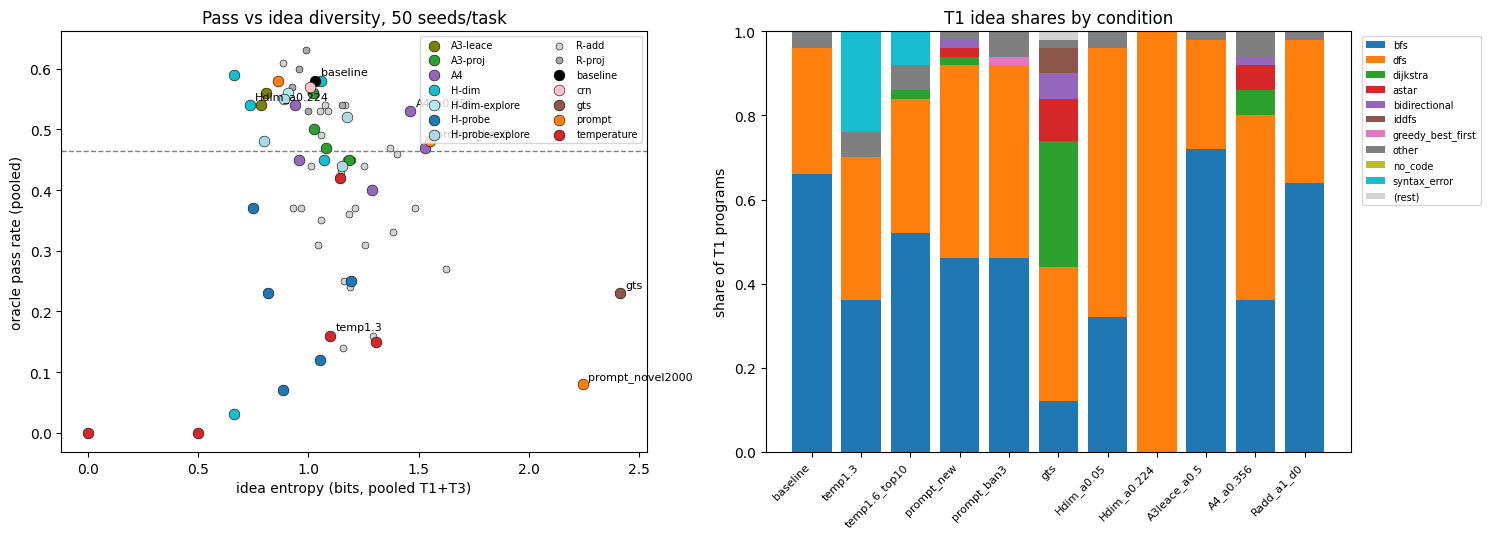

Survival verdicts (full run, pre-registered rules):
  H-probe   survives=False
  H-dim     survives=False
  A3-proj   survives=False
  A3-leace  survives=False
  A4        survives=False
  H-dim held-out entropy ratio vs best temperature: T1 0.93, T3 1.20 (needed >= 2)
Commitment point: algorithm name first appears at median token 23.5 (T1) / 46.5 (T3); never within the first 8 tokens

Live mini-sweep ( Qwen/Qwen2.5-0.5B-Instruct ):
  T1 baseline       labels=['dfs', 'dfs', 'dfs'] pass=[False, False, False]
  T1 temp1.6_top10  labels=['dfs', 'syntax_error', 'syntax_error'] pass=[False, False, False]
  T1 Radd_a1_d0     labels=['bfs', 'other', 'bfs'] pass=[True, False, False]


In [21]:
fam_colors = {"baseline": "black", "temperature": "tab:red", "prompt": "tab:orange", "gts": "tab:brown",
              "H-probe": "tab:blue", "H-dim": "tab:cyan", "H-probe-explore": "lightblue", "H-dim-explore": "paleturquoise",
              "A3-proj": "tab:green", "A3-leace": "olive", "A4": "tab:purple", "R-add": "lightgray", "R-proj": "darkgray",
              "crn": "pink"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
seen = set()
for name, row in table.items():
    f = row["family"]
    ax.scatter(row["pooled"]["entropy"], row["pooled"]["pass"], c=fam_colors.get(f, "gold"), s=60 if f not in ("R-add", "R-proj") else 25,
               edgecolor="k", linewidth=0.4, label=f if f not in seen else None, zorder=3 if f not in ("R-add", "R-proj") else 2)
    seen.add(f)
for name in ["baseline", "prompt_ban3", "gts", "Hdim_a0.224", "temp1.3", "prompt_novel2000", "A4_a0.356"]:
    if name in table:
        ax.annotate(name, (table[name]["pooled"]["entropy"], table[name]["pooled"]["pass"]), fontsize=8,
                    xytext=(4, 4), textcoords="offset points")
ax.axhline(0.8 * np.mean(list(base_pass.values())), ls="--", c="gray", lw=1)
ax.set_xlabel("idea entropy (bits, pooled T1+T3)"); ax.set_ylabel("oracle pass rate (pooled)")
ax.set_title(f"Pass vs idea diversity, {N_SWEEP_SEEDS} seeds/task"); ax.legend(fontsize=7, ncol=2, loc="upper right")

ax = axes[1]
show = ["baseline", "temp1.3", "temp1.6_top10", "prompt_new", "prompt_ban3", "gts", "Hdim_a0.05", "Hdim_a0.224",
        "A3leace_a0.5", "A4_a0.356", "Radd_a1_d0"]
show = [s for s in show if s in table]
labs = ["bfs", "dfs", "dijkstra", "astar", "bidirectional", "iddfs", "greedy_best_first", "other", "no_code", "syntax_error"]
cmap = plt.get_cmap("tab10")
bottom = np.zeros(len(show))
for j, lab in enumerate(labs + ["(rest)"]):
    vals = []
    for s in show:
        lc = table[s]["tasks"]["T1"]["label_counts"]; n = table[s]["tasks"]["T1"]["n"]
        vals.append((sum(v for k, v in lc.items() if k not in labs) if lab == "(rest)" else lc.get(lab, 0)) / n)
    ax.bar(range(len(show)), vals, bottom=bottom, color=cmap(j % 10) if lab != "(rest)" else "lightgray", label=lab)
    bottom += np.array(vals)
ax.set_xticks(range(len(show))); ax.set_xticklabels(show, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("share of T1 programs"); ax.set_title("T1 idea shares by condition")
ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

# key numbers recorded by the full run (not recomputed here: they need the GPU stages and the judge)
sv = META["survival"]
print("Survival verdicts (full run, pre-registered rules):")
for k in ("H-probe", "H-dim", "A3-proj", "A3-leace", "A4"):
    print(f"  {k:<9} survives={sv[k]['survives']}")
h = sv["H-dim"]
print(f"  H-dim held-out entropy ratio vs best temperature: T1 {h['T1']['ratio']:.2f}, T3 {h['T3']['ratio']:.2f} (needed >= 2)")
cp = META["commitment_point"]
print(f"Commitment point: algorithm name first appears at median token {cp['T1']['median_token']} (T1) / "
      f"{cp['T3']['median_token']} (T3); never within the first 8 tokens")
if RUN_LIVE_GENERATION:
    print("\nLive mini-sweep (", LIVE_MODEL_ID, "):")
    for (task, name), recs in live_scored.items():
        print(f"  {task} {name:<14} labels={[r['label'] for r in sorted(recs, key=lambda r: r['idx'])]} "
              f"pass={[r['pass'] for r in sorted(recs, key=lambda r: r['idx'])]}")